In [2]:
import os

print(os.listdir("/content"))

['.config', 'human+activity+recognition+using+smartphones.zip', 'sample_data']


In [3]:
import zipfile
import os

zip_path = "/content/human+activity+recognition+using+smartphones.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/")

print("Extraction completed!")
print(os.listdir("/content"))

Extraction completed!
['.config', 'UCI HAR Dataset.names', 'human+activity+recognition+using+smartphones.zip', 'UCI HAR Dataset.zip', 'sample_data']


In [5]:
import os

for root, dirs, files in os.walk("/content"):
    if "Inertial Signals" in root:
        print("Found:", root)
        print(files)

In [6]:
import os

for item in os.listdir("/content"):
    print(item)

.config
UCI HAR Dataset.names
human+activity+recognition+using+smartphones.zip
UCI HAR Dataset.zip
sample_data


In [7]:
import os

for root, dirs, files in os.walk("/content"):
    if files:
        print("\nFolder:", root)
        print("Files:", files[:5])


Folder: /content
Files: ['UCI HAR Dataset.names', 'human+activity+recognition+using+smartphones.zip', 'UCI HAR Dataset.zip']

Folder: /content/.config
Files: ['default_configs.db', 'gce', '.last_update_check.json', 'hidden_gcloud_config_universe_descriptor_data_cache_configs.db', 'config_sentinel']

Folder: /content/.config/logs/2026.10.26
Files: ['22.18.15.518759.log', '22.18.38.571729.log', '22.18.53.588181.log', '22.18.45.880512.log', '22.18.52.867204.log']

Folder: /content/.config/configurations
Files: ['config_default']

Folder: /content/sample_data
Files: ['anscombe.json', 'README.md', 'california_housing_train.csv', 'mnist_test.csv', 'mnist_train_small.csv']


In [8]:
import zipfile

zip_path = "/content/human+activity+recognition+using+smartphones.zip"

with zipfile.ZipFile(zip_path, 'r') as z:
    print("First 25 files inside ZIP:")
    for name in z.namelist()[:25]:
        print(name)

First 25 files inside ZIP:
UCI HAR Dataset.names
UCI HAR Dataset.zip


In [9]:
import zipfile
import os

# Extract the outer ZIP
outer_zip = "/content/human+activity+recognition+using+smartphones.zip"

with zipfile.ZipFile(outer_zip, 'r') as z:
    z.extractall("/content/")

print("Outer ZIP extracted!")

# Extract the inner ZIP
inner_zip = "/content/UCI HAR Dataset.zip"

with zipfile.ZipFile(inner_zip, 'r') as z:
    z.extractall("/content/")

print("Inner ZIP extracted successfully!")

Outer ZIP extracted!
Inner ZIP extracted successfully!


In [10]:
import os

dataset_path = "/content/UCI HAR Dataset"

print("Dataset contents:")
print(os.listdir(dataset_path))

Dataset contents:
['features_info.txt', 'README.txt', 'test', 'features.txt', '.DS_Store', 'activity_labels.txt', 'train']


In [11]:

import os
import numpy as np

base_path = "/content/UCI HAR Dataset"

# Sensor signal folder paths
train_path = os.path.join(base_path, "train", "Inertial Signals")
test_path = os.path.join(base_path, "test", "Inertial Signals")

# Six sensor signals
signals = [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",
    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z"
]

# Load training data
X_train = np.stack([
    np.loadtxt(os.path.join(train_path, signal + "_train.txt"))
    for signal in signals
], axis=-1)

# Load testing data
X_test = np.stack([
    np.loadtxt(os.path.join(test_path, signal + "_test.txt"))
    for signal in signals
], axis=-1)

# Load activity labels
y_train = np.loadtxt(
    os.path.join(base_path, "train", "y_train.txt")
).astype(int)

y_test = np.loadtxt(
    os.path.join(base_path, "test", "y_test.txt")
).astype(int)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


Training data shape: (7352, 128, 6)
Testing data shape: (2947, 128, 6)
Training labels: (7352,)
Testing labels: (2947,)


In [12]:

activity_labels = {
    1: "WALKING",
    2: "WALKING_UPSTAIRS",
    3: "WALKING_DOWNSTAIRS",
    4: "SITTING",
    5: "STANDING",
    6: "LAYING"
}

print("Activity distribution in training data:\n")

for label, name in activity_labels.items():
    count = np.sum(y_train == label)
    print(f"{label} - {name}: {count} samples")


Activity distribution in training data:

1 - WALKING: 1226 samples
2 - WALKING_UPSTAIRS: 1073 samples
3 - WALKING_DOWNSTAIRS: 986 samples
4 - SITTING: 1286 samples
5 - STANDING: 1374 samples
6 - LAYING: 1407 samples


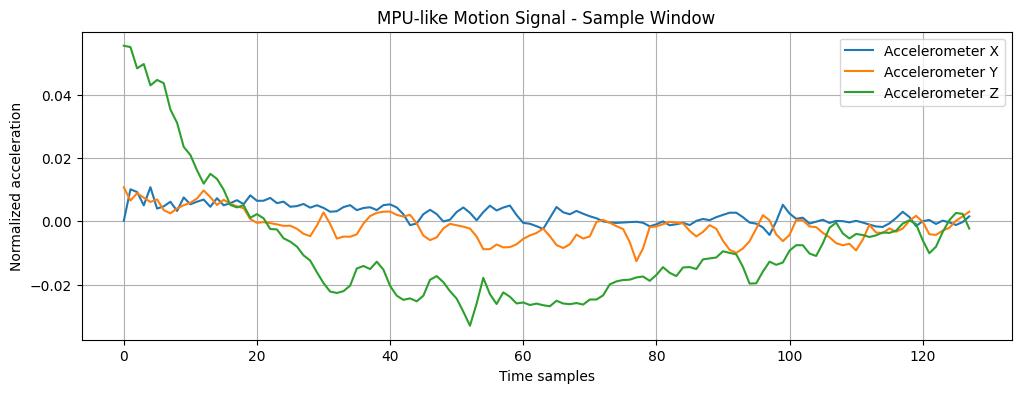

In [13]:

import matplotlib.pyplot as plt

sample = X_train[0]

plt.figure(figsize=(12, 4))

plt.plot(sample[:, 0], label="Accelerometer X")
plt.plot(sample[:, 1], label="Accelerometer Y")
plt.plot(sample[:, 2], label="Accelerometer Z")

plt.title("MPU-like Motion Signal - Sample Window")
plt.xlabel("Time samples")
plt.ylabel("Normalized acceleration")
plt.legend()
plt.grid()
plt.show()


In [14]:

import tensorflow as tf
from tensorflow.keras import layers, models

# Make labels start from 0 instead of 1
y_train_ml = y_train - 1
y_test_ml = y_test - 1

# Build a small 1D CNN
model = models.Sequential([
    layers.Input(shape=(128, 6)),

    layers.Conv1D(16, kernel_size=5, activation='relu'),
    layers.MaxPooling1D(pool_size=2),

    layers.Conv1D(32, kernel_size=3, activation='relu'),
    layers.MaxPooling1D(pool_size=2),

    layers.Flatten(),

    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(6, activation='softmax')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display model structure
model.summary()

# Train model
history = model.fit(
    X_train,
    y_train_ml,
    epochs=15,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 124, 16)        │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 62, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 60, 32)         │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        30,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,014 (128.96 KB)

 Trainable params: 33,014 (128.96 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.3564 - loss: 1.4224 - val_accuracy: 0.5520 - val_loss: 0.9534
Epoch 2/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.5734 - loss: 0.8683 - val_accuracy: 0.6370 - val_loss: 0.6737
Epoch 3/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.6232 - loss: 0.7124 - val_accuracy: 0.6356 - val_loss: 0.6350
Epoch 4/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.6467 - loss: 0.6626 - val_accuracy: 0.6581 - val_loss: 0.6209
Epoch 5/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6579 - loss: 0.6326 - val_accuracy: 0.6655 - val_loss: 0.6123
Epoch 6/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6564 - loss: 0.6163 - val_accuracy: 0.6907 - val_loss: 0.6109
Epoch 7/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.6674 - loss: 0.6003 - val_accuracy: 0.6485 - val_loss: 0.6094
Epoch 8/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6757 - loss: 0.5917 - val_accuracy: 0.6519 - v

Test Accuracy: 74.55 %

Classification Report:
                    precision    recall  f1-score   support

           Walking       0.99      0.94      0.96       496
  Walking Upstairs       0.86      0.96      0.91       471
Walking Downstairs       0.97      0.91      0.94       420
           Sitting       0.79      0.24      0.37       491
          Standing       0.46      0.94      0.62       532
            Laying       0.87      0.52      0.65       537

          accuracy                           0.75      2947
         macro avg       0.82      0.75      0.74      2947
      weighted avg       0.81      0.75      0.73      2947



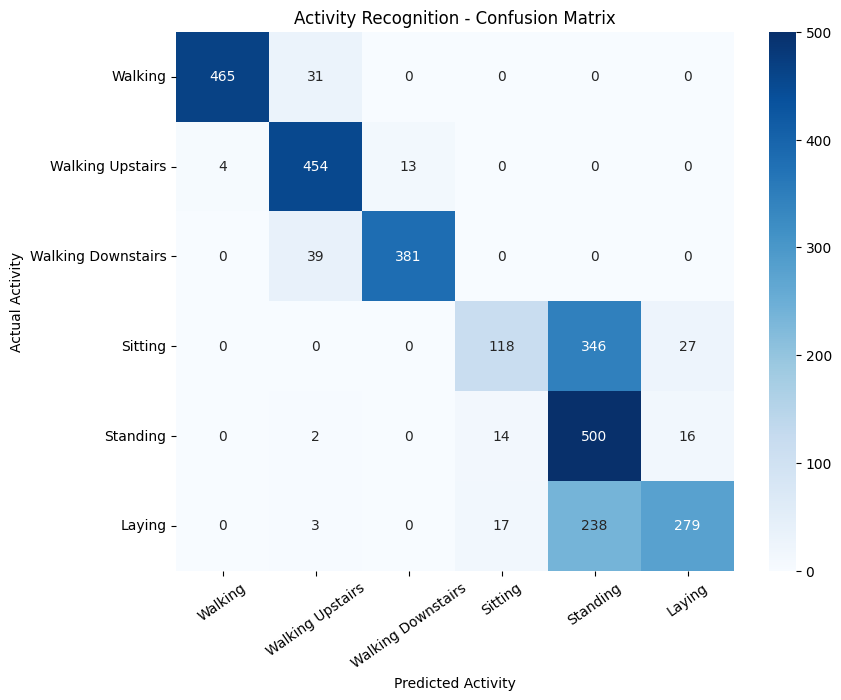

In [15]:

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Evaluate using the separate test dataset
test_loss, test_accuracy = model.evaluate(
    X_test, y_test_ml, verbose=0
)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

# Generate predictions
predictions = model.predict(X_test, verbose=0)
y_pred = predictions.argmax(axis=1)

# Detailed performance for each activity
class_names = [
    "Walking",
    "Walking Upstairs",
    "Walking Downstairs",
    "Sitting",
    "Standing",
    "Laying"
]

print("\nClassification Report:")
print(classification_report(
    y_test_ml,
    y_pred,
    target_names=class_names
))

# Confusion matrix
cm = confusion_matrix(y_test_ml, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.title("Activity Recognition - Confusion Matrix")
plt.xticks(rotation=35)
plt.yticks(rotation=0)
plt.show()


In [16]:

# Save original trained model
model.save("/content/activity_model.keras")

# Convert to TensorFlow Lite
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# Enable optimization
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# Representative dataset for quantization
def representative_dataset():
    for i in range(200):
        yield [X_train[i:i+1].astype("float32")]

converter.representative_dataset = representative_dataset

# Full integer quantization
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]

converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

# Convert
tflite_model = converter.convert()

# Save converted model
with open("/content/activity_model_int8.tflite", "wb") as f:
    f.write(tflite_model)

print("Model conversion completed!")

import os
print("TFLite model size:",
      round(os.path.getsize("/content/activity_model_int8.tflite") / 1024, 2),
      "KB")


Saved artifact at '/tmp/tmpcpz2h3fi'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 6), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  134381532839184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134381532837456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134381532839568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134381532839376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134381532838992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134381532839760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134381529022928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134381529023888: TensorSpec(shape=(), dtype=tf.resource, name=None)


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Model conversion completed!
TFLite model size: 41.92 KB


In [17]:

# Load the converted model
interpreter = tf.lite.Interpreter(
    model_path="/content/activity_model_int8.tflite"
)

interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("Input details:")
print(input_details)

print("\nOutput details:")
print(output_details)

print("\nInput data type:", input_details[0]["dtype"])
print("Output data type:", output_details[0]["dtype"])


Input details:
[{'name': 'serving_default_keras_tensor:0', 'index': 0, 'shape': array([  1, 128,   6], dtype=int32), 'shape_signature': array([ -1, 128,   6], dtype=int32), 'dtype': <class 'numpy.int8'>, 'quantization': (0.02383754588663578, 20), 'quantization_parameters': {'scales': array([0.02383755], dtype=float32), 'zero_points': array([20], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}]

Output details:
[{'name': 'StatefulPartitionedCall_1:0', 'index': 36, 'shape': array([1, 6], dtype=int32), 'shape_signature': array([-1,  6], dtype=int32), 'dtype': <class 'numpy.int8'>, 'quantization': (0.00390625, -128), 'quantization_parameters': {'scales': array([0.00390625], dtype=float32), 'zero_points': array([-128], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}]

Input data type: <class 'numpy.int8'>
Output data type: <class 'numpy.int8'>


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [18]:

input_info = input_details[0]
output_info = output_details[0]

input_scale, input_zero = input_info["quantization"]
output_scale, output_zero = output_info["quantization"]

correct = 0

for i in range(len(X_test)):
    sample = X_test[i:i+1].astype("float32")

    # Convert input to INT8
    quantized_input = np.round(
        sample / input_scale + input_zero
    ).clip(-128, 127).astype(np.int8)

    interpreter.set_tensor(
        input_info["index"], quantized_input
    )
    interpreter.invoke()

    output = interpreter.get_tensor(output_info["index"])

    # Convert output back to float
    probabilities = (
        output.astype("float32") - output_zero
    ) * output_scale

    predicted_class = np.argmax(probabilities)

    if predicted_class == y_test_ml[i]:
        correct += 1

print("Quantized model accuracy:",
      round(correct / len(X_test) * 100, 2), "%")


Quantized model accuracy: 72.51 %


In [19]:

# Convert TFLite model into a C header file

!xxd -i /content/activity_model_int8.tflite > /content/activity_model.h

print("C header generated successfully!")

import os
print("Header file size:",
      round(os.path.getsize("/content/activity_model.h") / 1024, 2),
      "KB")


/bin/bash: line 1: xxd: command not found
C header generated successfully!
Header file size: 0.0 KB


In [20]:
from google.colab import files

files.download("/content/activity_model.h")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
interpreter = tf.lite.Interpreter(
    model_path="/content/activity_model_int8.tflite"
)

interpreter.allocate_tensors()

ops = sorted(set(
    op["op_name"] for op in interpreter._get_ops_details()
))

print("Model operations:", ops)

Model operations: ['CONV_2D', 'DELEGATE', 'EXPAND_DIMS', 'FULLY_CONNECTED', 'MAX_POOL_2D', 'PACK', 'RESHAPE', 'SHAPE', 'SOFTMAX', 'STRIDED_SLICE']


In [22]:
!ls -lh /content/activity_model_int8.tflite

!xxd -i /content/activity_model_int8.tflite > /content/activity_model.h

!ls -lh /content/activity_model.h

!head -n 5 /content/activity_model.h

-rw-r--r-- 1 root root 42K Nov 24 09:32 /content/activity_model_int8.tflite
/bin/bash: line 1: xxd: command not found
-rw-r--r-- 1 root root 0 Nov 24 09:49 /content/activity_model.h


In [23]:
model_path = "/content/activity_model_int8.tflite"
header_path = "/content/activity_model.h"

with open(model_path, "rb") as f:
    model_data = f.read()

with open(header_path, "w") as f:
    f.write("#pragma once\n")
    f.write("#include <cstdint>\n\n")
    f.write("alignas(16) const unsigned char activity_model[] = {\n")

    for i in range(0, len(model_data), 12):
        chunk = model_data[i:i+12]
        f.write("  " + ", ".join(f"0x{b:02x}" for b in chunk) + ",\n")

    f.write("};\n")
    f.write(f"const unsigned int activity_model_len = {len(model_data)};\n")

print("Header generated successfully!")
print("Model size:", len(model_data), "bytes")

Header generated successfully!
Model size: 42928 bytes


In [24]:
from google.colab import files
files.download("/content/activity_model.h")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:

print("Input shape:", X_train.shape)

print("\nFirst 5 samples:")
print(X_train[0][:5])

print("\nMinimum values:")
print(X_train.min(axis=(0, 1)))

print("\nMaximum values:")
print(X_train.max(axis=(0, 1)))

print("\nMean values:")
print(X_train.mean(axis=(0, 1)))


Input shape: (7352, 128, 6)

First 5 samples:
[[0.00018085 0.01076681 0.05556068 0.03019122 0.06601362 0.02285864]
 [0.01013856 0.00657948 0.05512483 0.04371071 0.04269897 0.01031572]
 [0.00927557 0.00892888 0.04840473 0.0356878  0.07485018 0.01324969]
 [0.0050659  0.00748868 0.04977497 0.0404021  0.05731974 0.01775121]
 [0.01081025 0.00614097 0.04301314 0.04709654 0.05234284 0.00255337]]

Minimum values:
[-1.232238 -1.345267 -1.364707 -4.733656 -5.97433  -2.763014]

Maximum values:
[1.299912  0.9759764 1.066916  4.155473  5.746062  2.365982 ]

Mean values:
[-0.0006363  -0.0002923  -0.0002753   0.00050646 -0.00082378  0.00011295]
